# 1. Inspeção dos Dados

Base utilizada: **Breast Cancer Wisconsin (Diagnostic)**, com exames classificados como tumor maligno (`M`) ou benigno (`B`).

**Proveniência.** O conjunto foi criado por W. N. Street, W. H. Wolberg e O. L. Mangasarian (Universidade de Wisconsin, 1993) a partir de imagens digitalizadas de punção aspirativa por agulha fina (PAAF) de massas mamárias. A fonte primária é o UCI Machine Learning Repository, distribuído sob licença CC BY 4.0; a cópia usada neste projeto é a redistribuição do Kaggle, salva em `data/raw/breast_cancer_wisconsin.csv`.

- UCI: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- Kaggle: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

Esta etapa caracteriza a estrutura da base e identifica problemas de qualidade dos dados. Os dados não são modificados; os tratamentos necessários são listados ao final e aplicados na etapa de limpeza (`02_data_cleaning.ipynb`).


## 1.1 Importação das bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 12)


## 1.2 Carregamento da base

In [ ]:
DATA_PATH = "data.csv"

df = pd.read_csv(DATA_PATH)

## 1.3 Visualização inicial dos dados

In [ ]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,...,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,...,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,...,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,...,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,...,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,...,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,...,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,...,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,...,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,...,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,...,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,...,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


A visualização acima exibe apenas as primeiras e últimas colunas para caber na página; a lista completa está na seção 1.4.

Cada registro corresponde a um exame. Além de `id` e `diagnosis`, as colunas descrevem os núcleos celulares observados nas imagens de PAAF. São 10 características (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal), cada uma medida de três formas:

- `_mean`: média;
- `_se`: erro padrão;
- `_worst`: média dos três maiores valores.


## 1.4 Dimensões do dataset

In [ ]:
n_rows, n_cols = df.shape
print(f"Linhas: {n_rows}")
print(f"Colunas: {n_cols}")

Linhas: 569
Colunas: 33


In [ ]:
df.columns.tolist()

['id',
 'diagnosis',
 'radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst',
 'Unnamed: 32']

A base possui 569 registros e 33 colunas.

## 1.5 Informações gerais e tipos das variáveis

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.dtypes.value_counts()

,count
float64,31
int64,1
object,1


In [ ]:
[col for col in df.columns if " " in col or col.startswith("Unnamed")]

['concave points_mean',
 'concave points_se',
 'concave points_worst',
 'Unnamed: 32']

As 30 variáveis de medida foram lidas como `float64` e `diagnosis` é a única coluna textual. Há uma coluna não prevista, `Unnamed: 32`, gerada pela vírgula ao final do cabeçalho do CSV. As colunas `concave points_*` contêm espaço no nome.

## 1.6 Estatísticas descritivas

In [ ]:
df.drop(columns=["id"]).describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [ ]:
features = df.select_dtypes("number").drop(columns=["id"]).dropna(axis=1, how="all")

value_range = pd.DataFrame({"min": features.min(), "max": features.max()})
value_range["amplitude"] = value_range["max"] - value_range["min"]
value_range.sort_values("amplitude", ascending=False)

,min,max,amplitude
area_worst,185.200000,4254.00000,4068.800000
area_mean,143.500000,2501.00000,2357.500000
area_se,6.802000,542.20000,535.398000
perimeter_worst,50.410000,251.20000,200.790000
perimeter_mean,43.790000,188.50000,144.710000
texture_worst,12.020000,49.54000,37.520000
texture_mean,9.710000,39.28000,29.570000
radius_worst,7.930000,36.04000,28.110000
perimeter_se,0.757000,21.98000,21.223000
radius_mean,6.981000,28.11000,21.129000


In [ ]:
(features == 0).sum().loc[lambda s: s > 0]

,0
concavity_mean,13
concave points_mean,13
concavity_se,13
concave points_se,13
concavity_worst,13
concave points_worst,13


As variáveis apresentam escalas muito diferentes: as medidas de área chegam a 4.254, enquanto suavidade e dimensão fractal ficam abaixo de 1. Modelos sensíveis à escala, como KNN e regressão logística, exigirão padronização.

Há 13 exames com valor `0` nas seis colunas de concavidade e pontos côncavos. Como a ausência de concavidade é fisicamente possível, esses valores são considerados válidos, e não dados ausentes.

In [ ]:
shape = pd.DataFrame({
    "media": features.mean(),
    "mediana": features.median(),
    "assimetria": features.skew(),
})
shape["media/mediana"] = (shape["media"] / shape["mediana"]).round(2)
shape.sort_values("assimetria", ascending=False).round(3)


,media,mediana,assimetria,media/mediana
area_se,40.337,24.530,5.447,1.64
concavity_se,0.032,0.026,5.110,1.23
fractal_dimension_se,0.004,0.003,3.924,1.19
perimeter_se,2.866,2.287,3.444,1.25
radius_se,0.405,0.324,3.089,1.25
smoothness_se,0.007,0.006,2.314,1.10
symmetry_se,0.021,0.019,2.195,1.10
compactness_se,0.025,0.020,1.902,1.25
area_worst,880.583,686.500,1.859,1.28
fractal_dimension_worst,0.084,0.080,1.663,1.05


In [ ]:
q1, q3 = features.quantile(0.25), features.quantile(0.75)
iqr = q3 - q1
is_outlier = (features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)

outliers_by_col = is_outlier.sum().sort_values(ascending=False)
rows_with_outlier = is_outlier.any(axis=1)

print(f"Colunas com ao menos um outlier (IQR): {(outliers_by_col > 0).sum()} de {len(outliers_by_col)}")
print(f"Exames com ao menos um outlier: {rows_with_outlier.sum()} ({rows_with_outlier.mean() * 100:.1f}%)")
print("Por classe:")
print(df.loc[rows_with_outlier, "diagnosis"].value_counts().to_string())
outliers_by_col.head(10)


Colunas com ao menos um outlier (IQR): 29 de 30
Exames com ao menos um outlier: 171 (30.1%)
Por classe:
diagnosis
M    114
B     57


,0
area_se,65
radius_se,38
perimeter_se,38
area_worst,35
smoothness_se,30
fractal_dimension_se,28
compactness_se,28
symmetry_se,27
area_mean,25
fractal_dimension_worst,24


In [ ]:
print(f"Valores negativos: {(features < 0).sum().sum()}")
print(f"Colunas com mínimo igual a zero: {features.columns[features.min() == 0].tolist()}")

geometry = pd.DataFrame({
    "area / (pi * raio^2)": df["area_mean"] / (np.pi * df["radius_mean"] ** 2),
    "perimetro / (2 * pi * raio)": df["perimeter_mean"] / (2 * np.pi * df["radius_mean"]),
})
geometry.describe().T.round(3)


Valores negativos: 0
Colunas com mínimo igual a zero: ['concavity_mean', 'concave points_mean', 'concavity_se', 'concave points_se', 'concavity_worst', 'concave points_worst']


,count,mean,std,min,25%,50%,75%,max
area / (pi * raio^2),569.0,0.981,0.015,0.917,0.972,0.981,0.988,1.064
perimetro / (2 * pi * raio),569.0,1.033,0.021,0.983,1.017,1.030,1.044,1.133


**Assimetria.** Das 30 variáveis, 22 têm assimetria acima de 1 e 7 acima de 2, todas com cauda à direita. O caso mais forte é `area_se` (assimetria 5,4; média de 40 contra mediana de 24,5), seguido de `concavity_se` e `fractal_dimension_se`. As variáveis `_se` concentram as maiores distorções, o que é esperado para medidas de dispersão. Apenas as medidas de suavidade e `concave points_worst` ficam próximas da simetria.

**Outliers.** Pelo critério do intervalo interquartil, 29 das 30 variáveis têm valores extremos e 171 exames (30,1%) apresentam ao menos um. Desses, 114 são malignos e 57 benignos: os extremos estão concentrados na classe de interesse, o que indica que são casos clinicamente relevantes e não erros de medição. A recomendação para a limpeza é **não remover** esses registros; a etapa de pré-processamento deve considerar transformação logarítmica nas variáveis mais assimétricas ou um escalonador robusto a outliers.

**Consistência física.** Não há valores negativos. Os únicos zeros ocorrem nas seis colunas de concavidade, já discutidas acima. As razões geométricas entre área, perímetro e raio ficam próximas de 1 em todos os exames (área entre 0,92 e 1,06 do círculo equivalente; perímetro entre 0,98 e 1,13), como se espera de núcleos aproximadamente circulares. Não foram encontrados valores fisicamente impossíveis ou inconsistentes entre colunas relacionadas.


## 1.7 Verificação de valores ausentes

In [ ]:
missing = pd.DataFrame({
    "ausentes": df.isnull().sum(),
    "percentual": (df.isnull().mean() * 100).round(2),
})
missing[missing["ausentes"] > 0]

,ausentes,percentual
Unnamed: 32,569,100.0


In [ ]:
print(f"Total de valores ausentes: {df.isnull().sum().sum()}")
print(f"Total sem a coluna 'Unnamed: 32': {df.drop(columns=['Unnamed: 32'], errors='ignore').isnull().sum().sum()}")

Total de valores ausentes: 569
Total sem a coluna 'Unnamed: 32': 0


A única coluna com valores ausentes é `Unnamed: 32`, vazia em todos os 569 registros. As demais colunas estão completas.

## 1.8 Verificação de registros duplicados

In [ ]:
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"IDs duplicados: {df['id'].duplicated().sum()}")
print(f"Linhas duplicadas desconsiderando o id: {df.drop(columns=['id']).duplicated().sum()}")

Linhas duplicadas: 0
IDs duplicados: 0
Linhas duplicadas desconsiderando o id: 0


Não há registros duplicados, nem considerando o `id` nem desconsiderando-o, e cada `id` aparece uma única vez.

## 1.9 Distribuição inicial da variável diagnosis

In [ ]:
diagnosis_counts = pd.DataFrame({
    "quantidade": df["diagnosis"].value_counts(),
    "percentual": (df["diagnosis"].value_counts(normalize=True) * 100).round(2),
})
diagnosis_counts

,quantidade,percentual
diagnosis,,
B,357,62.74
M,212,37.26


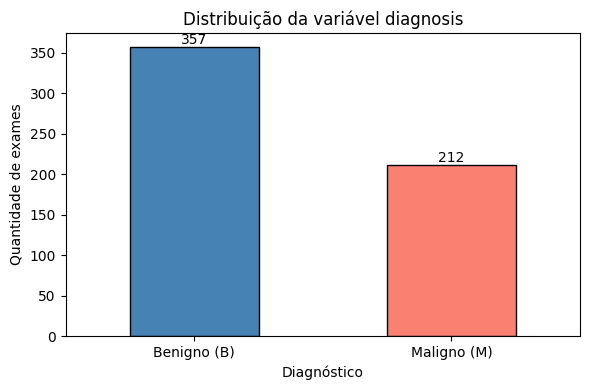

In [ ]:
ax = df["diagnosis"].value_counts().rename({"B": "Benigno (B)", "M": "Maligno (M)"}).plot(
    kind="bar", color=["steelblue", "salmon"], edgecolor="black", figsize=(6, 4)
)
ax.set_title("Distribuição da variável diagnosis")
ax.set_xlabel("Diagnóstico")
ax.set_ylabel("Quantidade de exames")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

A base tem 357 casos benignos (62,7%) e 212 malignos (37,3%). O desbalanceamento é moderado e não impede a modelagem, mas indica o uso de separação estratificada entre treino, validação e teste. Como um falso negativo (tumor maligno classificado como benigno) é o erro mais grave neste problema, o **recall** da classe maligna deve receber atenção especial na avaliação.

In [ ]:
mean_cols = [col for col in df.columns if col.endswith("_mean")]

by_class = df.groupby("diagnosis")[mean_cols].mean().T
by_class["razao M/B"] = (by_class["M"] / by_class["B"]).round(2)
by_class.sort_values("razao M/B", ascending=False).round(4)


diagnosis,B,M,razao M/B
concavity_mean,0.0461,0.1608,3.49
concave points_mean,0.0257,0.0880,3.42
area_mean,462.7902,978.3764,2.11
compactness_mean,0.0801,0.1452,1.81
perimeter_mean,78.0754,115.3654,1.48
radius_mean,12.1465,17.4628,1.44
texture_mean,17.9148,21.6049,1.21
smoothness_mean,0.0925,0.1029,1.11
symmetry_mean,0.1742,0.1929,1.11
fractal_dimension_mean,0.0629,0.0627,1.00


A comparação das médias por classe antecipa quais variáveis tendem a separar os diagnósticos. Concavidade e pontos côncavos são em média 3,4 a 3,5 vezes maiores nos tumores malignos, e a área é o dobro. Textura, suavidade e simetria diferem pouco entre as classes, e a dimensão fractal praticamente não muda (razão 1,00). Essa leitura é apenas indicativa e será aprofundada na análise exploratória, com distribuições por classe e matriz de correlação.


## 1.10 Conclusões da inspeção

A base contém 569 exames e 33 colunas: `id`, `diagnosis`, 30 variáveis numéricas de medida e uma coluna vazia (`Unnamed: 32`). Não há valores ausentes nas variáveis de medida, registros duplicados, valores negativos ou inconsistências geométricas entre colunas relacionadas. A variável alvo está distribuída em 357 casos benignos (62,7%) e 212 malignos (37,3%).

**Tratamentos indicados para a limpeza**

| Item | Situação encontrada | Tratamento |
|---|---|---|
| `Unnamed: 32` | 100% vazia, gerada pela vírgula ao final do cabeçalho | Remover |
| `id` | Identificador único, sem valor preditivo | Remover |
| `diagnosis` | Categórica (`M`/`B`), sem variantes de grafia | Converter para `1`/`0` |
| Valores ausentes | Nenhum nas variáveis de medida | Nenhum |
| Duplicatas | Nenhuma | Nenhum |
| Valores inconsistentes | Nenhum negativo ou fisicamente impossível | Nenhum |
| Zeros em concavidade | 13 exames, valores plausíveis | Manter |
| Outliers (IQR) | 171 exames (30,1%), 2/3 deles malignos | Manter; tratar na escala, não por exclusão |
| `concave points_*` | Espaço no nome da coluna | Renomear (opcional) |

**Implicações para as etapas seguintes**

- As diferenças de escala entre as variáveis exigem padronização no pipeline de pré-processamento.
- A forte assimetria à direita, sobretudo nas variáveis `_se`, sugere avaliar transformação logarítmica ou escalonador robusto antes de modelos sensíveis à escala.
- Os outliers concentram-se na classe maligna e não devem ser removidos, sob risco de descartar justamente os casos que o modelo precisa aprender.
- O desbalanceamento moderado entre as classes indica separação estratificada e avaliação por recall e F1-score, além da acurácia.
- Concavidade, pontos côncavos e área são as candidatas mais fortes a variáveis discriminantes e merecem destaque na análise exploratória.


## 2. Modelagem Preditiva e Avaliação de Performance

A partir desta etapa, iniciamos a fase de modelagem do projeto. O objetivo é construir e avaliar modelos capazes de classificar os exames como malignos (`M`) ou benignos (`B`) utilizando as características extraídas das imagens da PAAF.

### 2.1 Importação das Bibliotecas de Machine Learning
Na célula abaixo, importamos o algoritmo de **Regressão Logística** para modelagem, a função para dividir os dados em treino e teste, e as métricas básicas para mensurar a qualidade das classificações (Acurácia, Recall e F1-Score).

In [ ]:
# Segunda parte do projeto

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, f1_score

### 2.2 Inicialização do Modelo
Instanciamos o objeto da Regressão Logística básico para posterior treinamento.

In [ ]:
# Criar o modelo
modelo = LogisticRegression()

### 2.3 Preparação dos Atributos (X) e Variável Alvo (y)
Removemos as colunas identificadoras e nulas que não possuem poder preditivo (`diagnosis`, `id`, `Unnamed: 32`) para formar a matriz de recursos $X$. Isolamos a coluna `diagnosis` como nosso vetor alvo $y$.

In [ ]:
X = df.drop(columns=["diagnosis", "id", "Unnamed: 32"])

y = df.diagnosis

### 2.4 Divisão dos Dados
Dividimos os dados de forma a separar uma parcela para treino/validação e outra para testes independentes.

In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.50, random_state=42)

### 2.5 Treinamento do Modelo de Regressão Logística
Ajustamos o estimador de Regressão Logística com os dados de treino.

In [ ]:
modelo.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

### 2.6 Árvore de Decisão como Modelo Alternativo
Para fins de comparação, criamos e treinamos um modelo não-linear baseado em árvore de decisão (`DecisionTreeClassifier`).

In [ ]:
from sklearn.tree import DecisionTreeClassifier

modelo_arvore = DecisionTreeClassifier(random_state=42)
modelo_arvore.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### 2.7 Previsões e Primeira Avaliação
Realizamos previsões nos dados de teste com a Árvore de Decisão, comparamos visualmente os primeiros resultados e calculamos a acurácia global obtida.

In [ ]:
# o modelo faz previsões em dados que ele nunca viu (teste)
y_pred = modelo_arvore.predict(X_test)

# Comparando algumas previsões com o valor real
print("Comparação entre valor real e previsto:")
for i in range(10):
  # Usamos .iloc[i] para acessar a Series do pandas pela posição sequencial
  print(f"Real: {y_test.iloc[i]} | Previsto: {y_pred[i]}")

# calculando a acurácia (fora do loop)
acc_mlp = accuracy_score(y_test, y_pred)
print("\nAcurácia do modelo:", acc_mlp)

Comparação entre valor real e previsto:
Real: B | Previsto: B
Real: M | Previsto: M
Real: M | Previsto: M
Real: B | Previsto: B
Real: B | Previsto: B
Real: M | Previsto: M
Real: M | Previsto: M
Real: M | Previsto: M
Real: B | Previsto: M
Real: B | Previsto: B

Acurácia do modelo: 0.9438596491228071


### 2.8 Comparação Detalhada das Métricas
Calculamos e exibimos métricas críticas (Acurácia, Recall e F1-Score) focando na classe de interesse **Maligno (M)** para ambos os modelos treinados (Árvore de Decisão e Regressão Logística).

In [ ]:
print("=== Métricas do Modelo: Árvore de Decisão ===")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall (Maligno): {recall_score(y_test, y_pred, pos_label='M'):.4f}")
print(f"F1-Score (Maligno): {f1_score(y_test, y_pred, pos_label='M'):.4f}")

# Calculo também para a Regressão Logística que foi treinada anteriormente
y_pred_logistica = modelo.predict(X_test)
print("\n=== Métricas do Modelo: Regressão Logística ===")
print(f"Acurácia: {accuracy_score(y_test, y_pred_logistica):.4f}")
print(f"Recall (Maligno): {recall_score(y_test, y_pred_logistica, pos_label='M'):.4f}")
print(f"F1-Score (Maligno): {f1_score(y_test, y_pred_logistica, pos_label='M'):.4f}")

=== Métricas do Modelo: Árvore de Decisão ===
Acurácia: 0.9439
Recall (Maligno): 0.9388
F1-Score (Maligno): 0.9200

=== Métricas do Modelo: Regressão Logística ===
Acurácia: 0.9509
Recall (Maligno): 0.9286
F1-Score (Maligno): 0.9286


### 2.9 Otimização de Hiperparâmetros e Pré-Processamento (Pipeline)
Aqui estruturamos um fluxo robusto utilizando um `Pipeline` que realiza a padronização das escalas com `StandardScaler` e aplica a busca exaustiva de hiperparâmetros (`GridSearchCV`). O foco da busca é maximizar o **Recall** da classe maligna, que é a métrica clínica mais importante para evitar falsos negativos.

Melhores Parâmetros Encontrados:
{'logreg__C': 1, 'logreg__class_weight': 'balanced', 'logreg__penalty': 'l2'}

=== Regressão Logística Otimizada (Foco em Recall) ===
Acurácia: 0.9719
Recall (Maligno): 0.9796
F1-Score (Maligno): 0.9600


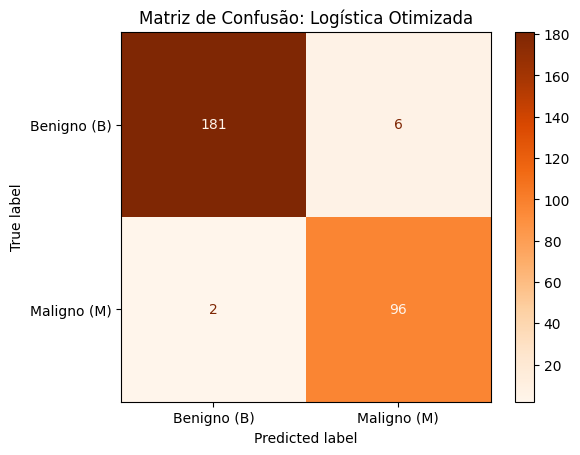

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Criando um Pipeline que primeiro padroniza os dados e depois aplica a Regressão Logística
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=10000, random_state=42))
])

# Definindo o espaço de parâmetros para busca
param_grid = {
    'logreg__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logreg__penalty': ['l2'],
    'logreg__class_weight': [None, 'balanced']
}

# Criando um scorer focado em Recall especificamente para a classe 'M'
recall_maligno_scorer = make_scorer(recall_score, pos_label='M')

# Configurando o GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=recall_maligno_scorer,
    cv=5,
    n_jobs=-1
)

# Ajustando o modelo nos dados de treino
grid_search.fit(X_train, y_train)

# Melhores parâmetros encontrados
best_pipeline = grid_search.best_estimator_
print("Melhores Parâmetros Encontrados:")
print(grid_search.best_params_)

# Avaliando nos dados de teste
y_pred_opt = best_pipeline.predict(X_test)

# Exibindo as métricas otimizadas
print("\n=== Regressão Logística Otimizada (Foco em Recall) ===")
print(f"Acurácia: {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"Recall (Maligno): {recall_score(y_test, y_pred_opt, pos_label='M'):.4f}")
print(f"F1-Score (Maligno): {f1_score(y_test, y_pred_opt, pos_label='M'):.4f}")

# Matriz de confusão para o novo modelo
cm_opt = confusion_matrix(y_test, y_pred_opt, labels=['B', 'M'])
disp_opt = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=['Benigno (B)', 'Maligno (M)'])
disp_opt.plot(cmap='Oranges', values_format='d')
plt.title("Matriz de Confusão: Logística Otimizada")
plt.show()

### 2.10 Relatório de Classificação Completo
Geramos o relatório detalhado de performance do modelo otimizado, avaliando Precisão, Recall e F1-Score para ambas as classes separadamente.

In [ ]:
from sklearn.metrics import classification_report

# Gerando o relatório de classificação completo
relatorio = classification_report(
    y_test,
    y_pred_opt,
    target_names=['Benigno (B)', 'Maligno (M)']
)

print("=== Relatório de Classificação: Regressão Logística Otimizada ===")
print(relatorio)

=== Relatório de Classificação: Regressão Logística Otimizada ===
              precision    recall  f1-score   support

 Benigno (B)       0.99      0.97      0.98       187
 Maligno (M)       0.94      0.98      0.96        98

    accuracy                           0.97       285
   macro avg       0.97      0.97      0.97       285
weighted avg       0.97      0.97      0.97       285



### 2.11 Instalação do SHAP para Interpretabilidade
Instalamos a biblioteca `shap` (Shapley Additive exPlanations) para obtermos uma explicação matemática sobre o impacto de cada variável nas decisões do modelo.

In [ ]:
%%capture
!pip install shap

### 2.12 Análise de Coeficientes do Modelo (Feature Importance Tradicional)
Analisamos os coeficientes finais da Regressão Logística para entender a direção e a força de associação de cada atributo com o diagnóstico.

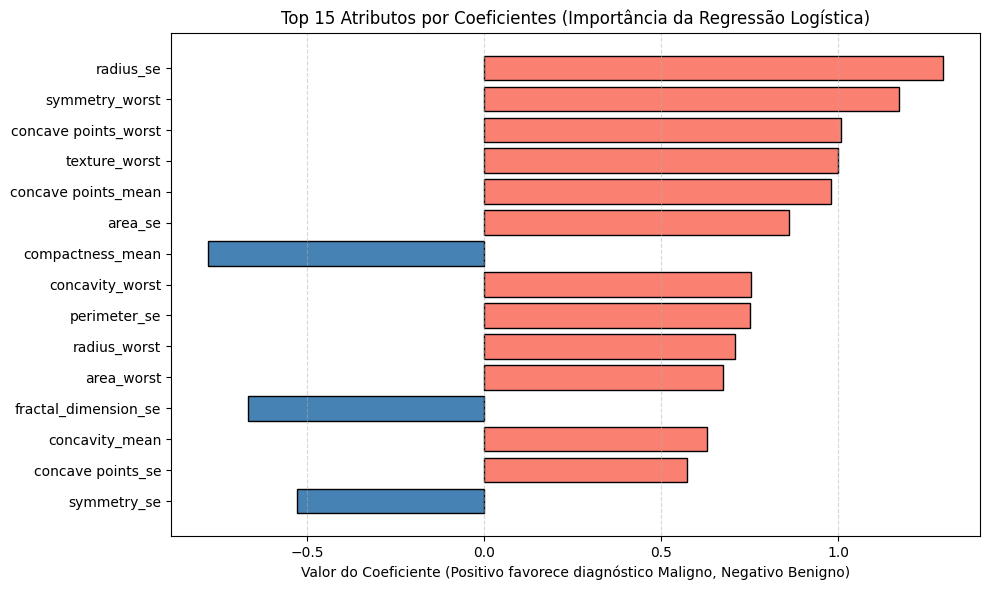

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. Feature Importance Tradicional (Coeficientes do Modelo)
# Extraímos o scaler e o modelo de dentro do pipeline otimizado
scaler = best_pipeline.named_steps['scaler']
modelo_logistica = best_pipeline.named_steps['logreg']

# Os coeficientes nos dão a importância direta para modelos lineares
coeficientes = modelo_logistica.coef_[0]
feature_names = X_train.columns

importancia_df = pd.DataFrame({
    'Atributo': feature_names,
    'Coeficiente': coeficientes,
    'Importancia_Absoluta': np.abs(coeficientes)
}).sort_values(by='Importancia_Absoluta', ascending=False)

# Plotando as 15 variáveis mais importantes por coeficientes
plt.figure(figsize=(10, 6))
plt.barh(importancia_df['Atributo'].head(15)[::-1], importancia_df['Coeficiente'].head(15)[::-1],
         color=['salmon' if c > 0 else 'steelblue' for c in importancia_df['Coeficiente'].head(15)[::-1]], edgecolor='black')
plt.title('Top 15 Atributos por Coeficientes (Importância da Regressão Logística)')
plt.xlabel('Valor do Coeficiente (Positivo favorece diagnóstico Maligno, Negativo Benigno)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 2.13 Análise de Atribuição de Impacto SHAP
Criamos um explicador SHAP para mapear como os valores altos e baixos de cada feature alteram as probabilidades preditas de forma global no conjunto de teste.

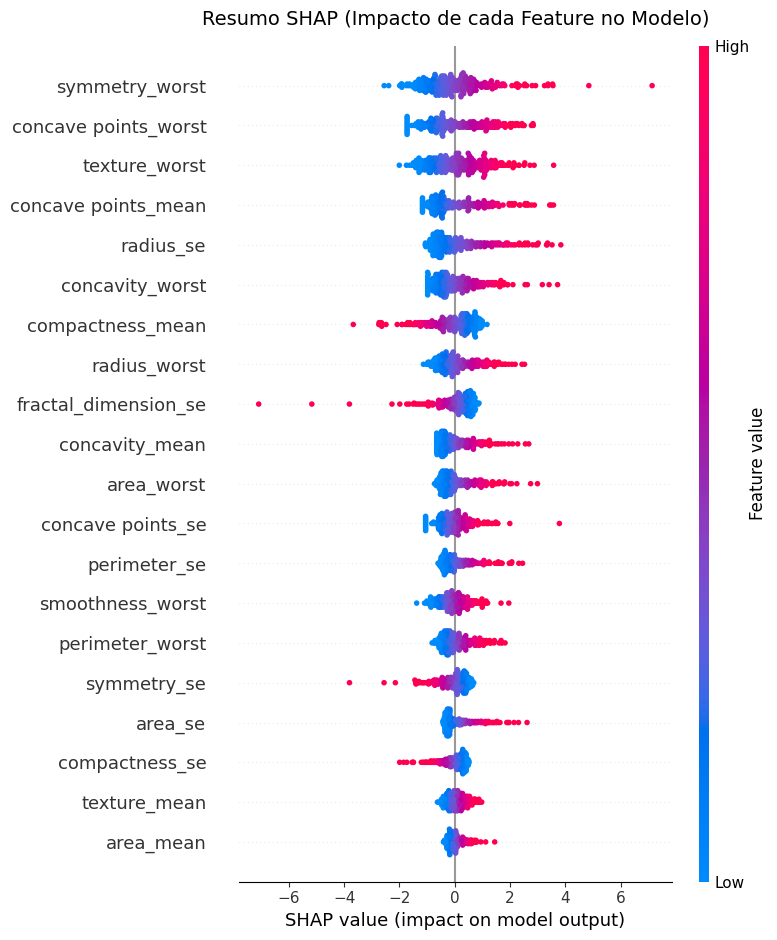

In [ ]:
# 2. Análise SHAP (Shapley Additive exPlanations)
# Primeiro precisamos transformar os dados de teste usando o scaler do pipeline
X_test_scaled = scaler.transform(X_test)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=feature_names)

# Criamos o explicador SHAP específico para modelos lineares
explainer = shap.LinearExplainer(modelo_logistica, X_test_scaled_df)
shap_values = explainer.shap_values(X_test_scaled_df)

# Plot Global de Importância SHAP (Summary Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_scaled_df, feature_names=feature_names, show=False)
plt.title('Resumo SHAP (Impacto de cada Feature no Modelo)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## 2.14 Análise de Componentes Principais (PCA)

O PCA é uma técnica de aprendizado não supervisionado que projeta nossos dados de alta dimensão (30 recursos) em uma nova base de coordenadas ortogonais (Componentes Principais), ordenados pela quantidade de variância que capturam do dataset original.

### 2.14.1 Aplicação do PCA e Variância Explicada

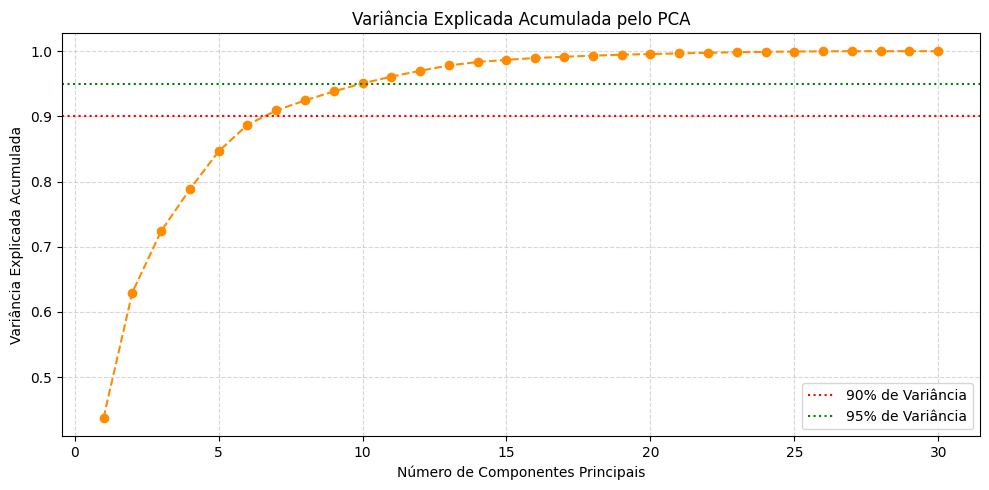

Com apenas 10 componentes principais conseguimos reter 95% de toda a variância original do dataset (de 30 variáveis).


In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

# Como o PCA é altamente sensível à escala, utilizaremos o Scaler que já ajustamos no treino
# Vamos aplicar o PCA sobre todos os dados (X) apenas para fins de visualização de toda a base
X_scaled = scaler.transform(X)

# Inicializamos o PCA sem definir número de componentes para analisar a variância acumulada
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

# Calculamos a variância acumulada
variancia_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Plotando a variância explicada acumulada
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', linestyle='--', color='darkorange')
plt.title('Variância Explicada Acumulada pelo PCA')
plt.xlabel('Número de Componentes Principais')
plt.ylabel('Variância Explicada Acumulada')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(y=0.90, color='r', linestyle=':', label='90% de Variância')
plt.axhline(y=0.95, color='g', linestyle=':', label='95% de Variância')
plt.legend()
plt.tight_layout()
plt.show()

# Mostrar quantos componentes explicam 95%
n_95 = np.argmax(variancia_acumulada >= 0.95) + 1
print(f"Com apenas {n_95} componentes principais conseguimos reter 95% de toda a variância original do dataset (de 30 variáveis).")

### 2.14.2 Projeção Visual em 2D dos Dois Primeiros Componentes
Vamos projetar e plotar as amostras usando apenas os dois primeiros componentes principais (PC1 e PC2) para verificar se existe uma separação natural clara entre tumores benignos e malignos.

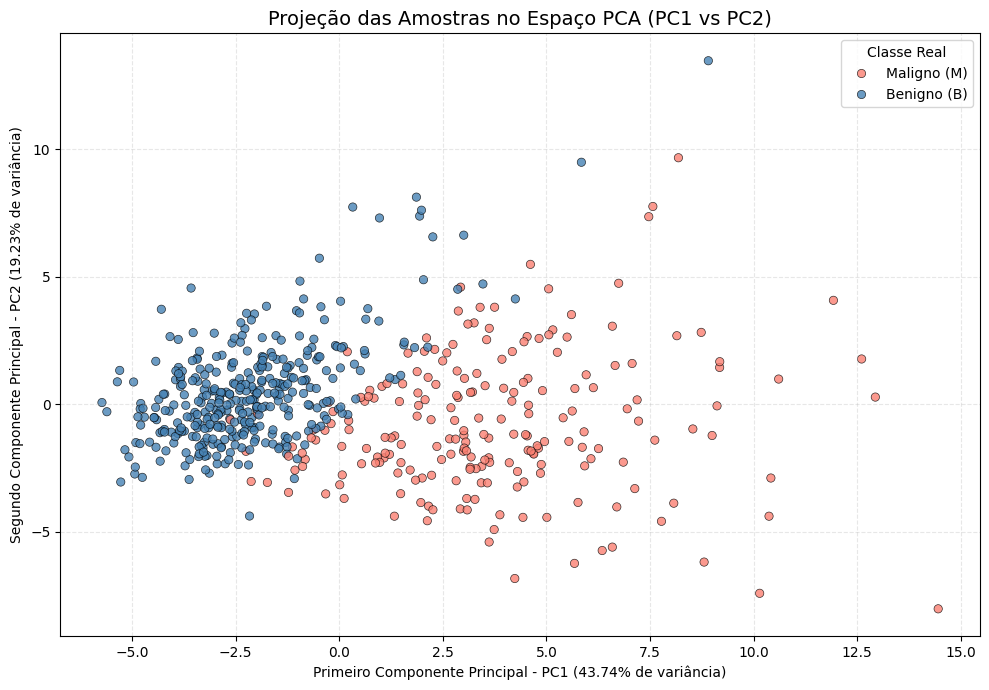

In [ ]:
# Aplicando PCA para 2 componentes
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Criando um DataFrame auxiliar para o plot
pca_df = pd.DataFrame(data=X_pca_2d, columns=['PC1', 'PC2'])
pca_df['Diagnóstico'] = y.values
pca_df['Diagnóstico'] = pca_df['Diagnóstico'].map({'B': 'Benigno (B)', 'M': 'Maligno (M)'})

# Plotando os dados projetados no espaço 2D do PCA
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Diagnóstico',
    palette={'Benigno (B)': 'steelblue', 'Maligno (M)': 'salmon'},
    data=pca_df,
    alpha=0.8,
    edgecolor='black'
)

plt.title('Projeção das Amostras no Espaço PCA (PC1 vs PC2)', fontsize=14)
plt.xlabel(f'Primeiro Componente Principal - PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% de variância)')
plt.ylabel(f'Segundo Componente Principal - PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% de variância)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title='Classe Real')
plt.tight_layout()
plt.show()

In [ ]:
X_train

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,...,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
423,13.660,19.13,89.46,575.3,0.09057,0.11470,...,0.11470,0.31670,0.36600,0.14070,0.2744,0.08839
546,10.320,16.35,65.31,324.9,0.09434,0.04994,...,0.12850,0.08842,0.04384,0.02381,0.2681,0.07399
119,17.950,20.01,114.20,982.0,0.08402,0.06722,...,0.10720,0.12020,0.22490,0.11850,0.4882,0.06111
386,12.210,14.09,78.78,462.0,0.08108,0.07823,...,0.10260,0.24310,0.30760,0.09140,0.2677,0.08824
367,12.210,18.02,78.31,458.4,0.09231,0.07175,...,0.13680,0.21700,0.24130,0.08829,0.3218,0.07470
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,8.888,14.64,58.79,244.0,0.09783,0.15310,...,0.12070,0.24360,0.14340,0.04786,0.2254,0.10840
106,11.640,18.33,75.17,412.5,0.11420,0.10170,...,0.16880,0.26600,0.28730,0.12180,0.2806,0.09097
270,14.290,16.82,90.30,632.6,0.06429,0.02675,...,0.08567,0.05036,0.03866,0.03333,0.2458,0.06120
435,13.980,19.62,91.12,599.5,0.10600,0.11330,...,0.16130,0.35680,0.40690,0.18270,0.3179,0.10550


In [ ]:
y_train

,diagnosis
423,B
546,B
119,M
386,B
367,B
...,...
71,B
106,B
270,B
435,M
